<a href="https://colab.research.google.com/github/menneli/PDA-1/blob/Lab_2/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PDA 26/27 · ЛР2. Работа с PySpark

**Максимум — 16 баллов.**

Решения пишите с помощью DataFrame API или Spark SQL. Не используйте `toPandas()` для вычислений — только для вывода небольших результатов.

## Данные

[BTS On-Time Performance](https://www.transtats.bts.gov/Tables.asp?QO_VQ=EFD&QO_anzr=Nv4yv0r%FDb0-gvzr%FDcr4s14zn0pr%FDQn6n&QO_fu146_anzr=b0-gvzr) — данные об авиаперевозках в США с 1987 года. Ниже скачивается часть 2023 и 2024 годов (11 CSV-файлов, ~6 млн рейсов).

Колонки, которые понадобятся: `FL_DATE` — дата рейса, `OP_UNIQUE_CARRIER` — код перевозчика, `ORIGIN` / `DEST` — аэропорты вылета и прилета, `ORIGIN_CITY_NAME` / `DEST_CITY_NAME` — города, `CANCELLED` — рейс отменен (1.0), `DISTANCE` — расстояние в милях, `CARRIER_DELAY`, `WEATHER_DELAY`, `NAS_DELAY`, `SECURITY_DELAY`, `LATE_AIRCRAFT_DELAY` — минуты задержки по причинам ([описание полей](https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGJ)).

## Подготовка

In [ ]:
# Установка библиотек (~1 минута)
!pip install -q "pyspark==4.2.*" "polars>=1.40" "dask[dataframe]" gdown

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 4.2.0 which is incompatible.


In [ ]:
import os, re, subprocess

def java_major():
    try:
        out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
    except FileNotFoundError:
        return 0
    m = re.search(r'version "(\d+)', out)
    return int(m.group(1)) if m else 0

if java_major() < 17:
    !apt-get -qq update > /dev/null && apt-get -qq install -y openjdk-17-jdk-headless > /dev/null
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

print("Java", java_major())

Java 21


In [ ]:
# Данные: BTS On-Time Performance, 2023–2024
import glob, gdown

FILE_IDS = ['1NQuold7jvGZfHikbvtj0QynbhM90pT8L', '1HNAGhPHE6BmamcI0D767-BFhF4BWs6Hh', '1ERgltJRuybLl7sIUUVckzpUVzyP1ttCq', '1XrUk6ZYwQLQTjtsMHKxzzERP4dCLMEao', '1qy95Qpd93VClYPethMtMDJdAMBl21fnW', '1js5pbc_xe6kP7W4_lp6HaeXR0oAw2ZDL', '1qb4_uKGy0KU_4jRzaauqeObaaCQMtdBZ', '1TuC71TgrJDgpOvQVKl9jn89fAr9El1Pa', '1nt7e9Pszf2-IB3GsKHNRHZ_SPzxS0E2L', '1V5tCiD9jRCss0KoJxk-r1zOCw3onwez3', '1WsKGiVBV2p-sgiDePT6HZKUezWPc2zUH']
N_FILES = len(FILE_IDS)

if len(glob.glob("T_ONTIME_REPORTING*.csv")) < N_FILES:
    for fid in FILE_IDS[:N_FILES]:
        gdown.download(id=fid, quiet=True)

FILES = sorted(glob.glob("T_ONTIME_REPORTING*.csv"))[:N_FILES]
CSV_GLOB = "T_ONTIME_REPORTING*.csv"
print(len(FILES), "файлов:", FILES[:3], "...")

11 файлов: ['T_ONTIME_REPORTING 10.csv', 'T_ONTIME_REPORTING 11.csv', 'T_ONTIME_REPORTING 2.csv'] ...


In [ ]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
import pyspark.sql.types as T

spark = (
    SparkSession.builder
    .master("local[*]")                          # локальный режим: все ядра этой машины
    .appName("PDA-lab2")
    .config("spark.driver.memory", "6g")         # в local-режиме драйвер = исполнитель
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.execution.pythonUDF.arrow.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark

In [ ]:
schema = T.StructType([
    T.StructField("YEAR", T.IntegerType()),
    T.StructField("FL_DATE", T.StringType()),
    T.StructField("OP_UNIQUE_CARRIER", T.StringType()),
    T.StructField("ORIGIN_AIRPORT_ID", T.IntegerType()),
    T.StructField("ORIGIN", T.StringType()),
    T.StructField("ORIGIN_CITY_NAME", T.StringType()),
    T.StructField("DEST_AIRPORT_ID", T.IntegerType()),
    T.StructField("DEST", T.StringType()),
    T.StructField("DEST_CITY_NAME", T.StringType()),
    T.StructField("DEP_DELAY", T.DoubleType()),
    T.StructField("ARR_DELAY", T.DoubleType()),
    T.StructField("CANCELLED", T.DoubleType()),
    T.StructField("ACTUAL_ELAPSED_TIME", T.DoubleType()),
    T.StructField("DISTANCE", T.DoubleType()),
    T.StructField("CARRIER_DELAY", T.DoubleType()),
    T.StructField("WEATHER_DELAY", T.DoubleType()),
    T.StructField("NAS_DELAY", T.DoubleType()),
    T.StructField("SECURITY_DELAY", T.DoubleType()),
    T.StructField("LATE_AIRCRAFT_DELAY", T.DoubleType()),
])

df = spark.read.csv(CSV_GLOB, header=True, schema=schema)
df.show(5)

+----+--------------------+-----------------+-----------------+------+--------------------+---------------+----+--------------+---------+---------+---------+-------------------+--------+-------------+-------------+---------+--------------+-------------------+
|YEAR|             FL_DATE|OP_UNIQUE_CARRIER|ORIGIN_AIRPORT_ID|ORIGIN|    ORIGIN_CITY_NAME|DEST_AIRPORT_ID|DEST|DEST_CITY_NAME|DEP_DELAY|ARR_DELAY|CANCELLED|ACTUAL_ELAPSED_TIME|DISTANCE|CARRIER_DELAY|WEATHER_DELAY|NAS_DELAY|SECURITY_DELAY|LATE_AIRCRAFT_DELAY|
+----+--------------------+-----------------+-----------------+------+--------------------+---------------+----+--------------+---------+---------+---------+-------------------+--------+-------------+-------------+---------+--------------+-------------------+
|2023|7/1/2023 12:00:00 AM|               9E|            10135|   ABE|Allentown/Bethleh...|          10397| ATL|   Atlanta, GA|     -4.0|    -17.0|      0.0|              117.0|   692.0|         NULL|         NULL|     N

Примеры по основным функциям PySpark — в ноутбуке Лекции 3 и в [Getting Started with PySpark](https://colab.research.google.com/drive/1noKypPI5ymbofp0YPtRH9gYSqNPAiTAT?usp=sharing).

## Задание 1 (1 балл)

1. Сколько различных перевозчиков представлено в датасете?
2. Какие 5 перевозчиков выполнили больше всего рейсов?

Могут понадобиться методы: `select()`, `distinct()` или `dropDuplicates()`, `count()`, `groupBy()`, `orderBy()`, `limit()`.

In [ ]:
df.createOrReplaceTempView("flights")
#количество перевозчиков в датасете
spark.sql("""
SELECT COUNT(DISTINCT OP_UNIQUE_CARRIER )
FROM flights
""").show()

# какие перевозчики выполнили больше всего рейсов
spark.sql("""
SELECT OP_UNIQUE_CARRIER, COUNT(FL_DATE) AS counter
FROM flights
WHERE CANCELLED == 0.0
GROUP BY OP_UNIQUE_CARRIER
ORDER BY counter DESC
LIMIT 5
""").show()

+---------------------------------+
|count(DISTINCT OP_UNIQUE_CARRIER)|
+---------------------------------+
|                               15|
+---------------------------------+

+-----------------+-------+
|OP_UNIQUE_CARRIER|counter|
+-----------------+-------+
|               WN|1290452|
|               DL| 882283|
|               AA| 849409|
|               UA| 648489|
|               OO| 602769|
+-----------------+-------+



## Задание 2 (3 балла)

Найдите 10 самых частых направлений, если:
1. направление — пара «аэропорт вылета — аэропорт прилета»;
2. направление — пара «город вылета — город прилета»;
3. направление — город прилета.

Одинаковы ли ответы в пунктах 1 и 2? Объясните, почему.

Могут понадобиться методы: `groupBy()`, `count()`, `orderBy()`, `limit()`.

In [ ]:
# аэропорт вылета - аэропорт прилета
print("Аэропорт вылета - аэропорт прилета")
spark.sql(
    """
    SELECT ORIGIN, ORIGIN_CITY_NAME, DEST, DEST_CITY_NAME,
      COUNT(FL_DATE) AS counter
    FROM flights
    WHERE CANCELLED = 0.0
    GROUP BY ORIGIN, ORIGIN_CITY_NAME, DEST, DEST_CITY_NAME
    ORDER BY counter DESC
    LIMIT 10
    """
).show()

# город вылета - город прилета
print("Город вылета - город прилета")
spark.sql(
    """
    SELECT ORIGIN_CITY_NAME, DEST_CITY_NAME,
      COUNT(FL_DATE) AS counter
    FROM flights
    WHERE CANCELLED = 0.0
    GROUP BY ORIGIN_CITY_NAME, DEST_CITY_NAME
    ORDER BY  counter DESC
    LIMIT 10
    """
).show()

# направление - город прилета
print("Направление - город прилета")
spark.sql("""
SELECT DEST_CITY_NAME,
      COUNT(FL_DATE) AS counter
    FROM flights
    WHERE CANCELLED = 0.0
    GROUP BY DEST_CITY_NAME
    ORDER BY  counter DESC
    LIMIT 10
""").show()



Аэропорт вылета - аэропорт прилета
+------+-----------------+----+-----------------+-------+
|ORIGIN| ORIGIN_CITY_NAME|DEST|   DEST_CITY_NAME|counter|
+------+-----------------+----+-----------------+-------+
|   HNL|     Honolulu, HI| OGG|      Kahului, HI|  11359|
|   OGG|      Kahului, HI| HNL|     Honolulu, HI|  11335|
|   LAX|  Los Angeles, CA| SFO|San Francisco, CA|  10368|
|   SFO|San Francisco, CA| LAX|  Los Angeles, CA|  10353|
|   LAX|  Los Angeles, CA| LAS|    Las Vegas, NV|   9451|
|   LAS|    Las Vegas, NV| LAX|  Los Angeles, CA|   9426|
|   JFK|     New York, NY| LAX|  Los Angeles, CA|   9021|
|   LAX|  Los Angeles, CA| JFK|     New York, NY|   9012|
|   ORD|      Chicago, IL| LGA|     New York, NY|   8879|
|   LGA|     New York, NY| ORD|      Chicago, IL|   8873|
+------+-----------------+----+-----------------+-------+

Город вылета - город прилета
+----------------+--------------+-------+
|ORIGIN_CITY_NAME|DEST_CITY_NAME|counter|
+----------------+--------------+------

Ответы в пункте 1-2 отличаются, так как в одном аэропорту может быть несколько аэропортов.

## Задание 3 (4 балла)

1. Создайте колонку `MONTH` с номером месяца рейса. Для этого разберите строку `FL_DATE` (формат `1/1/2024 12:00:00 AM`): либо через `split()` + `getItem()` + `cast()`, либо через `to_timestamp()` + `month()`.
2. Узнайте, сколько было отмен рейсов в каждом месяце. Отсортируйте ответ по числу отмен.
3. Для каждого месяца определите причину задержки, из-за которой было отложено больше всего рейсов. Причины — колонки `CARRIER_DELAY`, `WEATHER_DELAY`, `NAS_DELAY`, `SECURITY_DELAY`, `LATE_AIRCRAFT_DELAY`; рейс считается отложенным по причине, если значение в колонке больше 0.

Могут понадобиться методы и функции: `withColumn()`, `split()`, `getItem()`, `cast()`, `groupBy()`, `agg()`, `sum()`, `when()`, `otherwise()`, `col()`, `isNotNull()`, `greatest()`, `orderBy()`. Колонка `MONTH` понадобится в заданиях 5.

In [ ]:
from pyspark.sql.functions import split, when, col, greatest

df = (
    df
    .withColumn("FL_DATE", F.to_date(F.to_timestamp("FL_DATE", "M/d/yyyy h:mm:ss a")))
    .withColumn("MONTH", F.month("FL_DATE"))
)

# сколько было отменено рейсов в каждом месяце
df.createOrReplaceTempView("flights")

spark.sql("""
  SELECT MONTH,
    SUM(CASE WHEN CANCELLED > 0 THEN 1 ELSE 0 END) AS cancelled_c
  FROM flights
  GROUP BY MONTH
  ORDER BY cancelled_c DESC
""").show()

# определение для каждого месяца максимальной причины задержки
df_delays = (
    df
    .withColumn("carrier_bool", when(col("CARRIER_DELAY") > 0, 1).otherwise(0))
    .withColumn("weather_bool", when(col("WEATHER_DELAY") > 0, 1).otherwise(0))
    .withColumn("nas_bool", when(col("NAS_DELAY") > 0, 1).otherwise(0))
    .withColumn("security_bool", when(col("SECURITY_DELAY") > 0, 1).otherwise(0))
    .withColumn("late_bool", when(col("LATE_AIRCRAFT_DELAY") > 0, 1).otherwise(0))
)
grouped = df_delays.groupBy("MONTH").agg(
    F.sum("carrier_bool").alias("carrier_cnt"),
    F.sum("weather_bool").alias("weather_cnt"),
    F.sum("nas_bool").alias("nas_cnt"),
    F.sum("security_bool").alias("security_cnt"),
    F.sum("late_bool").alias("late_cnt"),
)

result = grouped.withColumn(
    "max_delay",
    greatest("carrier_cnt", "weather_cnt", "nas_cnt", "security_cnt","late_cnt")).withColumn(
        "reason",
        when(col("max_delay") == col("carrier_cnt"), "CARRIER_DELAY")
    .when(col("max_delay") == col("weather_cnt"), "WEATHER_DELAY")
    .when(col("max_delay") == col("nas_cnt"), "NAS_DELAY")
    .when(col("max_delay") == col("security_cnt"), "SECURITY_DELAY")
    .when(col("max_delay") == col("late_cnt"), "LATE_AIRCRAFT_DELAY")
).orderBy("max_delay")

pdf = result.toPandas()[['MONTH', 'max_delay', 'reason']]
pdf


+-----+-----------+
|MONTH|cancelled_c|
+-----+-----------+
|    1|      30684|
|    7|      14606|
|    6|      12219|
|    4|       9589|
|    8|       9172|
|    2|       9019|
|    3|       7406|
|    5|       3310|
|   12|       2310|
|   11|        819|
+-----+-----------+



,MONTH,max_delay,reason
0,11,44524,CARRIER_DELAY
1,12,50008,CARRIER_DELAY
2,2,52610,CARRIER_DELAY
3,5,62261,CARRIER_DELAY
4,4,71710,CARRIER_DELAY
5,8,73114,CARRIER_DELAY
6,3,74965,CARRIER_DELAY
7,6,87780,CARRIER_DELAY
8,7,96439,CARRIER_DELAY
9,1,129636,CARRIER_DELAY


## Задание 4 (2 балла)

В колонке `ORIGIN_CITY_NAME` город записан как `Atlanta, GA`. Выделите штат (две последние буквы) тремя способами:

1. обычной Python `udf` (`F.udf(..., "string", useArrow=False)`);
2. `pandas_udf`;
3. встроенными функциями (`F.split`, `F.element_at` или `F.substring_index`).

Для каждого способа посчитайте число рейсов по штатам и выведите топ-5 штатов. Сравните время и объясните результат: почему встроенные функции быстрее? Когда без UDF не обойтись?

In [ ]:
import time
from pyspark.sql.types import StringType
from pyspark.sql.functions import pandas_udf
def timeit(action, label):
    t = time.perf_counter(); res = action(); print(f"{label}: {time.perf_counter() - t:.2f} с"); return res

def python_ord(df):
  def extract(city_name):
    return city_name.split(",")[-1].strip() if city_name else None

  extract_state_udf = F.udf(extract, "string", useArrow=False)
  result = (
      df.withColumn("STATE", extract_state_udf(
          F.col("ORIGIN_CITY_NAME"))).groupBy("STATE").count().orderBy(F.desc(
              "count")).limit(5))
  return result.toPandas()


def pandas_ord(df):
  @pandas_udf(StringType())
  def extract(city_name_series):
    return city_name_series.str.split(",").str[-1].str.strip()
  result = (
      df.withColumn("STATE", extract(
          F.col("ORIGIN_CITY_NAME"))).groupBy("STATE").count().orderBy(
              F.desc("count")).limit(5))

  return result.toPandas()

def spark_ord(df):
  result = (((df.withColumn("STATE",
                                 F.element_at(F.split(F.col("ORIGIN_CITY_NAME"), ", "), -1)
                                 ))).groupBy("STATE").count().orderBy(
              F.desc("count")).limit(5))
  return result.toPandas()

names = [("обычный Python", python_ord), ("pandas_udf", pandas_ord), ("Встроенные функции", spark_ord)]
for name, f in names:
   res = timeit(lambda: f(df), name)
   display(res)



обычный Python: 23.99 с


,STATE,count
0,CA,670215
1,TX,651195
2,FL,572283
3,NY,343000
4,GA,327426


pandas_udf: 18.72 с


,STATE,count
0,CA,670215
1,TX,651195
2,FL,572283
3,NY,343000
4,GA,327426


Встроенные функции: 12.12 с


,STATE,count
0,CA,670215
1,TX,651195
2,FL,572283
3,NY,343000
4,GA,327426


Встроенные функции оказались быстрее, так как все процессы работают внутри JVM, не обращаясь к Python.
Если же нужную логику нельзя выразить встроенными функциями Spark или SQL и нужны сторонние библиотеки, тогда без UDF не обойтись.

## Задание 5 (6 баллов)

Создайте и обучите модель логистической регрессии для предсказания отмены рейса в [Spark MLlib](https://spark.apache.org/docs/latest/ml-guide.html).

Закодируйте категориальные признаки в one-hot формат: столбец из \(n\) категорий превращается в вектор длины \(n\) (в MLlib — \(n-1\)), где единица стоит в позиции категории объекта. Сначала [`StringIndexer`](https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.ml.feature.StringIndexer.html) превращает строки в индексы, затем [`OneHotEncoder`](https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.ml.feature.OneHotEncoder.html) — индексы в разреженные векторы.

Закодируем так столбец с перевозчиком (`OP_UNIQUE_CARRIER`).

In [ ]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder

carr_indexer = StringIndexer(inputCol="OP_UNIQUE_CARRIER", outputCol="carrier_index", handleInvalid="keep")
carr_encoder = OneHotEncoder(inputCol="carrier_index", outputCol="carrier_fact")

Столбцы `ORIGIN` (пункт вылета) и `DEST` (пункт прилета) закодируйте аналогично самостоятельно. Назовите результаты `origin_fact` и `dest_fact`.

In [ ]:
origin_indexer = StringIndexer(inputCol="ORIGIN", outputCol="origin_index", handleInvalid="keep")
origin_encoder = OneHotEncoder(inputCol="origin_index", outputCol="origin_fact")

dest_indexer = StringIndexer(inputCol="DEST", outputCol="dest_index", handleInvalid="keep")
dest_encoder = OneHotEncoder(inputCol="dest_index", outputCol="dest_fact")

Выделите целевую переменную. Ее важно назвать `label`: по этому названию `LogisticRegression` отличит ее от признаков. Целевая переменная — значения столбца `CANCELLED` (отмена рейса), приведенные к целому типу.

In [ ]:
df_ml = df.withColumn("label", F.col("CANCELLED").cast("int"))

Соберите все признаки, которые будут использоваться для обучения, в один вектор `features` с помощью [`VectorAssembler`](https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.ml.feature.VectorAssembler.html). В столбце `MONTH` лежит месяц рейса (задание 3).

In [ ]:
from pyspark.ml.feature import VectorAssembler

vec_assembler = VectorAssembler(inputCols=["MONTH", "DISTANCE", "carrier_fact", "dest_fact", "origin_fact"],
                                outputCol="features")

Объедините все предобработки в один [`Pipeline`](https://spark.apache.org/docs/latest/ml-pipeline.html): кодирование категориальных переменных и сборку матрицы признаков.

In [ ]:
from pyspark.ml import Pipeline

flights_pipe = Pipeline(stages=[dest_indexer, dest_encoder, carr_indexer, carr_encoder,
                                origin_indexer, origin_encoder, vec_assembler])

Разделите датасет на обучающую и тестовую выборки. Пайплайн предобработки обучайте только на обучающей выборке, чтобы не допустить утечки данных.

In [ ]:
training, test = df_ml.randomSplit([0.7, 0.3], seed=42)

prep = flights_pipe.fit(training)
train_p = prep.transform(training).cache()
test_p = prep.transform(test)

Создайте модель — логистическую регрессию.

In [ ]:
from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(maxIter=20)  # если обучается супердолго и нет сил ждать, уменьшите maxIter

Введите метрику качества — ROC-AUC, площадь под ROC-кривой. Кривая строится по долям верно и ложно классифицированных объектов (TPR и FPR) при разных порогах. Чем ближе ROC-AUC к 1, тем качественнее классификатор; 0.5 соответствует случайным предсказаниям.

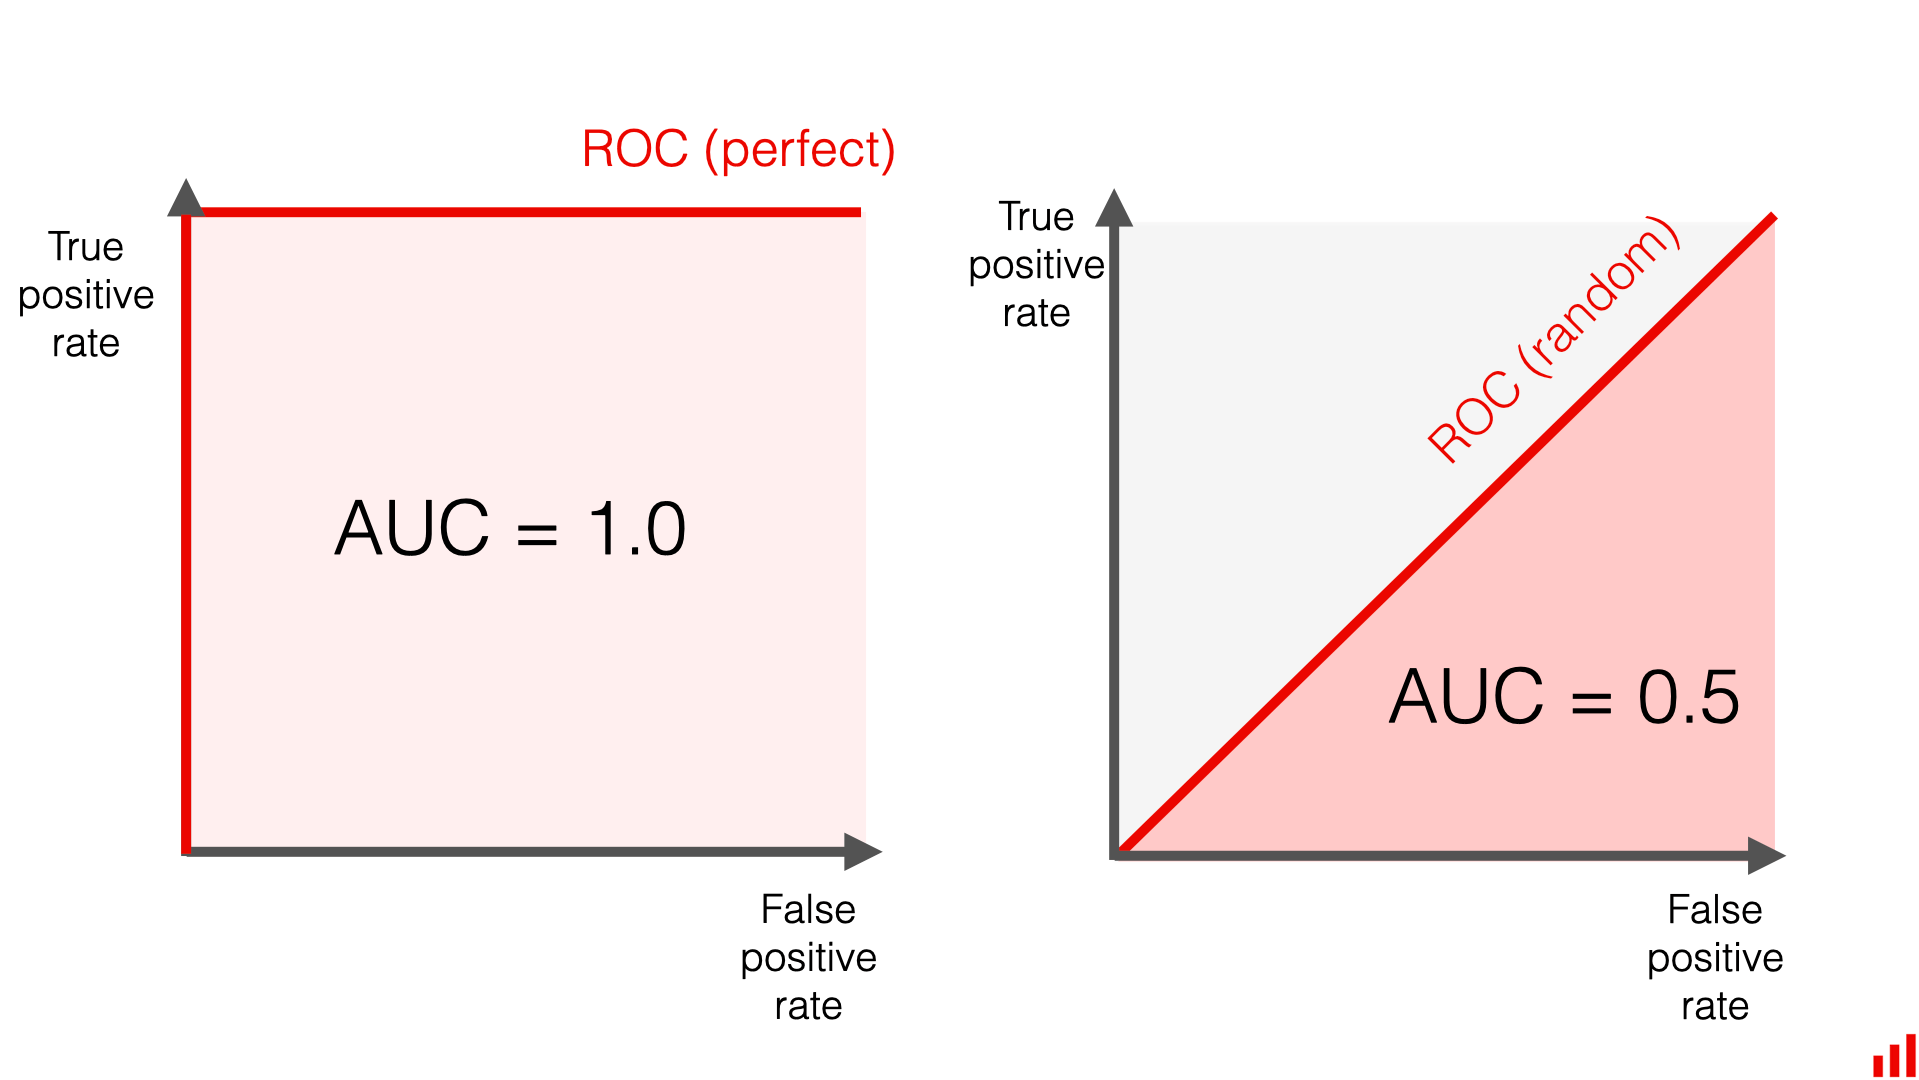

In [ ]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

evaluator = BinaryClassificationEvaluator(metricName="areaUnderROC")

Обучите модель и оцените ее на тестовой выборке.

In [ ]:
model = lr.fit(train_p)
test_results = model.transform(test_p)
print("ROC-AUC:", round(evaluator.evaluate(test_results), 4))

ROC-AUC: 0.6781


ROC-AUC базовой модели получается около 0.67 — результат посредственный. Проведите эксперименты с признаками. Базовый набор: `OP_UNIQUE_CARRIER`, `ORIGIN`, `DEST` (категориальные) и `MONTH`, `DISTANCE` (числовые).

Проведите несколько экспериментов, чтобы узнать, даст ли иное сочетание признаков более высокое качество предсказаний – выполните инженерию признаков:
1. Повысится ли качество, если не использовать данные о перевозчике?
2. Повысится ли качество, если задать направление полета иначе (см. задание 2: города вместо аэропортов)?
3. Повысится ли качество, если добавить дату рейса целиком как категориальный признак (`FL_DAY`, строка вида `1/15/2024`)? Чем дата отличается от месяца для задачи про отмены?
4. Повысится ли качество, если добавить комбинированный признак: "аэропорт вылета + месяц" (`ORIGIN_MONTH`, например `JFK_1`)?

Найдите сочетание признаков с наибольшим ROC-AUC: можно комбинировать добавленные признаки и убирать лишние. Какой прирост к базовой модели вы получили (в абсолютных единицах ROC-AUC)?

**Ответьте на вопросы:**

1. Отмененных рейсов около 1–2 %. Почему для такой задачи метрика accuracy плохо подходит, а ROC-AUC — лучше?
2. Обучающая и тестовая выборки получены случайным разбиением, поэтому в обучающей выборке есть рейсы того же дня, что и в тестовой. Честная ли это оценка для прогноза на будущее? Проверьте: обучите базовую модель и лучшую модель на рейсах первых месяцев, а оцените на последних (для этого нужны данные хотя бы за 4–5 месяцев, то есть `N_FILES` не меньше 4–5).

In [ ]:
# для ускорения экспериментов можно взять часть выборки
sample = df_ml.sample(fraction=0.3, seed=42)
train_s, test_s = sample.randomSplit([0.7, 0.3], seed=42)
train_s.cache(); test_s.cache()
print("Обучающая:", train_s.count(), "тестовая:", test_s.count())

Обучающая: 1308684 тестовая: 560104


Напишите функцию `evaluate(cat_cols, num_cols)`: она строит `Pipeline` из `StringIndexer` + `OneHotEncoder` для каждого категориального признака, `VectorAssembler` и `LogisticRegression(maxIter=20)`, обучает его на `train_s` и возвращает ROC-AUC на `test_s`.

In [ ]:
def evaluate(cat_cols, num_cols):
    idx_cols = [c + '_index' for c in cat_cols]
    fact_cols = [c + '_fact' for c in cat_cols]

    indexer = StringIndexer(inputCols=cat_cols, outputCols=idx_cols, handleInvalid='keep')
    encoder = OneHotEncoder(inputCols=idx_cols, outputCols=fact_cols, handleInvalid='keep')
    assembler = VectorAssembler(inputCols=list(num_cols) + fact_cols, outputCol='features')

    lr = LogisticRegression(maxIter=20, regParam=0.01)

    pipeline = Pipeline(stages=[indexer, encoder, assembler, lr])
    model = pipeline.fit(train_s)
    predictions = model.transform(test_s)
    return evaluator.evaluate(predictions)

Проведите эксперименты и сведите результаты в таблицу.

In [ ]:
df_features = df_ml.withColumn(
    "FL_DAY", F.date_format("FL_DATE", "M/d/yyyy")
).withColumn(
    "ORIGIN_MONTH",
    F.concat_ws("_", F.col("ORIGIN"), F.col("MONTH").cast("string"))
).cache()
df_features.count()

train_s, test_s = df_features.randomSplit([0.8, 0.2], seed=42)
train_s = train_s.cache()
test_s = test_s.cache()
train_s.count(); test_s.count()

experiments = [
    ("Базовая модель", ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST"], ["MONTH", "DISTANCE"]),
    ("Без перевозчика", ["ORIGIN", "DEST"], ["MONTH", "DISTANCE"]),
    ("Города вместо аэропортов", ["OP_UNIQUE_CARRIER", "ORIGIN_CITY_NAME", "DEST_CITY_NAME"], ["MONTH", "DISTANCE"]),
    ("С полной датой", ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "FL_DAY"], ["MONTH", "DISTANCE"]),
    ("С аэропортом и месяцем", ["OP_UNIQUE_CARRIER", "DEST", "ORIGIN_MONTH"], ["MONTH", "DISTANCE"]),
    ("Дата и аэропорт с месяцем", ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "FL_DAY", "ORIGIN_MONTH"], ["MONTH", "DISTANCE"]),
]

results = []
for name, cat_cols, num_cols in experiments:
    t = time.time()
    score = evaluate(cat_cols, num_cols)
    print(f"{name}: {score:.4f} ({time.time() - t:.0f}s)")
    results.append((name, cat_cols, num_cols, score))

results_df = spark.createDataFrame(
    [(name, score) for name, _, _, score in results], ["Эксперимент", "ROC-AUC"]
)
results_df.orderBy(F.desc("ROC-AUC")).show(truncate=False)

base_score = next(score for name, _, _, score in results if name == "Базовая модель")
best_name, best_cat_cols, best_num_cols, best_score = max(results, key=lambda x: x[3])

train_s.unpersist(); test_s.unpersist()

time_data = (
    df_features.sample(fraction=0.3, seed=42)
    .withColumn("date_num", F.unix_timestamp(F.col("FL_DATE").cast("timestamp")))
    .cache()
)
time_data.count()

cutoff = time_data.approxQuantile("date_num", [0.7], 0.01)[0]
train_s = time_data.filter(F.col("date_num") <= cutoff).cache()
test_s = time_data.filter(F.col("date_num") > cutoff).cache()
train_s.count(); test_s.count()

t = time.time()
base_time_score = evaluate(["OP_UNIQUE_CARRIER", "ORIGIN", "DEST"], ["MONTH", "DISTANCE"])
print(f"Базовая (time split): {base_time_score:.4f} ({time.time() - t:.0f}s)")

t = time.time()
best_time_score = evaluate(best_cat_cols, best_num_cols)
print(f"Лучшая (time split): {best_time_score:.4f} ({time.time() - t:.0f}s)")

time_results = [
    ("Базовая модель", base_time_score),
    (f"Лучшая модель ({best_name})", best_time_score),
]
spark.createDataFrame(
    time_results, ["Модель", "ROC-AUC на более поздних датах"]
).show(truncate=False)

Базовая модель: 0.6784 (68s)
Без перевозчика: 0.6710 (58s)
Города вместо аэропортов: 0.6780 (68s)
С полной датой: 0.8107 (87s)
С аэропортом и месяцем: 0.7428 (71s)
Дата и аэропорт с месяцем: 0.8242 (101s)
+-------------------------+------------------+
|Эксперимент              |ROC-AUC           |
+-------------------------+------------------+
|Дата и аэропорт с месяцем|0.8242287602296644|
|С полной датой           |0.810691510650577 |
|С аэропортом и месяцем   |0.7427946961955798|
|Базовая модель           |0.6783652375849671|
|Города вместо аэропортов |0.6779899728496502|
|Без перевозчика          |0.670957663442806 |
+-------------------------+------------------+

Базовая (time split): 0.4695 (24s)
Лучшая (time split): 0.4944 (32s)
+-----------------------------------------+------------------------------+
|Модель                                   |ROC-AUC на более поздних датах|
+-----------------------------------------+------------------------------+
|Базовая модель               

1. ROC-AUC снизился с 0,6784 до 0,6710
2. ROC-AUC составил 0,6780, что чуток ниже базового результата 0,6784
3. С полной датой ROC-AUC вырос до 0,8107. Месяц показывает только сезонность, а полная дата позволяет модели учитывать различия между конкретными днями (из-за погоды могли отменить рейс и тд)
4. ROC-AUC вырос до 0,7428. Это значит, что вероятность отмены рейса из конкретного аэропорта может меняться в зависимости от месяца

1. Отменённые рейсы составлют оч маленькое кол-во рейсов. Поэтому модель, которая всегда предсказывает, что рейс не будет отменён, получит accuracy около 98–99%. ROC-AUC оценивает, насколько хорошо модель различает отменённые и неотменённые рейсы. Пэтому эта метрика эффективнее
2. Думаю, что нет, так как при случайном разбиении в обучающей и тестовой выборках могут оказаться рейсы из одних и тех же дней. Будут учитываться закономерности, связанные с датами, которые присутствуют и в тестовой выборке. При прогнозе на будущее такой информации ещё нет.



In [ ]:
spark.stop()

# Куда сдавать?

Создайте новую ветку в уже существующем репозитории с первой лабораторной и загрузите в нее выполненный колаб. Туда же можете прикрепить колаб со второй практической работой.